# SD-004 — Retail Demand Analysis
This notebook analyzes the exported synthetic CSV tables as a retail demand-planning analyst. All records are fictional.



## 1. Question and approach
How do daily sales vary by store, product, weekday, promotion, and inventory availability? I will inspect the data, define each comparison, then evaluate a simple chronological baseline.



In [79]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
PROJECT_DIR = Path(__file__).resolve().parents[2] / "Sprint1" if "__file__" in globals() else Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = Path(__file__).resolve().parent / "analysis_outputs" if "__file__" in globals() and Path(__file__).suffix != ".ipynb" else PROJECT_DIR.parent / "legacy" / "Sprint1" / "analysis_outputs"
REFERENCE_DIR = PROJECT_DIR / "reference_data"
KEY = ["date", "store_id", "product_id"]



## 2. Inspect the exported data
First check keys, missing values, ranges, and table relationships before calculating metrics.



In [80]:
def load_tables(data_dir=DATA_DIR):
    data_dir = Path(data_dir)
    return {
        "stores": pd.read_csv(data_dir / "stores.csv"),
        "products": pd.read_csv(data_dir / "products.csv"),
        "calendar": pd.read_csv(data_dir / "calendar.csv", keep_default_na=False),
        "sales": pd.read_csv(data_dir / "daily_sales.csv", keep_default_na=False),
        "promotions": pd.read_csv(data_dir / "promotions.csv"),
        "inventory": pd.read_csv(data_dir / "inventory_snapshots.csv"),
    }


if __name__ == "__main__":
    tables = load_tables()
    print({name: len(table) for name, table in tables.items()})



{'stores': 5, 'products': 5, 'calendar': 120, 'sales': 3000, 'promotions': 3000, 'inventory': 3000}


In [81]:
def validate_and_join(tables):
    stores, products, calendar = tables["stores"], tables["products"], tables["calendar"]
    sales, promotions, inventory = tables["sales"], tables["promotions"], tables["inventory"]
    assert stores.store_id.is_unique and products.product_id.is_unique and calendar.date.is_unique
    assert not sales.duplicated(KEY).any()
    assert not promotions.duplicated(KEY).any() and not inventory.duplicated(KEY).any()
    assert set(sales.store_id) <= set(stores.store_id)
    assert set(sales.product_id) <= set(products.product_id)
    assert set(sales.date) <= set(calendar.date)
    analysis = sales.merge(promotions, on=KEY).merge(inventory, on=KEY).merge(calendar, on="date").merge(stores, on="store_id").merge(products, on="product_id")
    analysis["date"] = pd.to_datetime(analysis["date"])
    analysis["weekday_name"] = analysis.date.dt.day_name()
    analysis = analysis.sort_values("date")
    assert len(analysis) == len(sales) == 3000
    assert analysis.isna().sum().sum() == 0
    return analysis


if __name__ == "__main__":
    analysis = validate_and_join(tables)
    print(f"Joined rows: {len(analysis)}; missing values: {int(analysis.isna().sum().sum())}")



Joined rows: 3000; missing values: 0


## 3. Review the reference and calibration
The M5 reference is a daily item-store panel. A reproducible random sample informed weekday ratios only. Compare those target ratios with the generated data; this is a calibration check, not real-retailer validation.



The synthetic ratios differ slightly from the M5 targets because this is one small seeded realization with other effects. We keep the calibrated factors; we do not tune them repeatedly to force one synthetic sample to match the reference.



In [82]:
def calibrate_weekday(analysis, reference_dir=REFERENCE_DIR):
    reference = pd.read_csv(Path(reference_dir) / "calibration_summary.csv")
    reference = reference[reference.metric == "weekday_relative_to_monday"].copy()
    reference[["weekday", "reference_ratio"]] = reference.value.str.split("=", expand=True)
    reference["reference_ratio"] = reference.reference_ratio.astype(float)
    reference = reference.set_index("weekday").loc[WEEKDAY_ORDER]
    means = analysis.groupby("weekday_name").units_sold.mean().reindex(WEEKDAY_ORDER)
    return pd.DataFrame({
        "weekday": WEEKDAY_ORDER,
        "reference_ratio": reference.reference_ratio.values,
        "synthetic_ratio": (means / means.loc["Monday"]).values,
    })


if __name__ == "__main__":
    calibration = calibrate_weekday(analysis)
    print(calibration.round(3).to_string(index=False))



  weekday  reference_ratio  synthetic_ratio
   Monday            1.000            1.000
  Tuesday            0.925            0.928
Wednesday            0.908            0.900
 Thursday            0.911            0.906
   Friday            1.032            1.054
 Saturday            1.247            1.218
   Sunday            1.243            1.260


## 4. Describe sales patterns
Start with basic counts and averages. These summaries describe the generated dataset only.



In [83]:
def summarize_sales(analysis):
    overall = pd.DataFrame([
        {"metric": "rows", "value": len(analysis)},
        {"metric": "date_start", "value": analysis.date.min().date()},
        {"metric": "date_end", "value": analysis.date.max().date()},
        {"metric": "total_units", "value": analysis.units_sold.sum()},
        {"metric": "mean_units", "value": analysis.units_sold.mean()},
        {"metric": "promotion_share", "value": analysis.is_promotion.mean()},
        {"metric": "stockout_rows", "value": analysis.stockout_flag.sum()},
    ])
    store_product = analysis.groupby(["store_name", "product_name"], as_index=False).agg(
        mean_daily_units=("units_sold", "mean"), total_units=("units_sold", "sum")
    )
    promotion_summary = analysis.groupby("is_promotion").units_sold.agg(
        rows="count", mean_units="mean", median_units="median"
    ).reset_index()
    promotion_summary["status"] = promotion_summary.is_promotion.map({False: "No promotion", True: "Promotion"})
    stockouts = analysis[analysis.stockout_flag | analysis.edge_case.eq("forced_stockout")][
        ["date", "store_name", "product_name", "units_sold", "available_units", "stockout_flag", "edge_case"]
    ].copy()
    return overall, store_product, promotion_summary, stockouts


if __name__ == "__main__":
    overall, store_product, promotion_summary, stockouts = summarize_sales(analysis)
    print("Overall sample:\n", overall.to_string(index=False))
    print("\nTop store-product means:\n", store_product.nlargest(5, "mean_daily_units").to_string(index=False))
    print("\nPromotion groups:\n", promotion_summary.to_string(index=False))
    print("\nStockout rows:", len(stockouts))



Overall sample:
          metric      value
           rows       3000
     date_start 2025-01-01
       date_end 2025-04-30
    total_units      40965
     mean_units     13.655
promotion_share   0.037333
  stockout_rows          6

Top store-product means:
     store_name product_name  mean_daily_units  total_units
  South Market       Apples         25.275000         3033
Hilltop Market       Apples         24.033333         2884
  South Market         Milk         21.116667         2534
Hilltop Market         Milk         20.166667         2420
Central Market       Apples         19.541667         2345

Promotion groups:
  is_promotion  rows  mean_units  median_units       status
        False  2888   13.387812          12.5 No promotion
         True   112   20.544643          19.5    Promotion

Stockout rows: 6


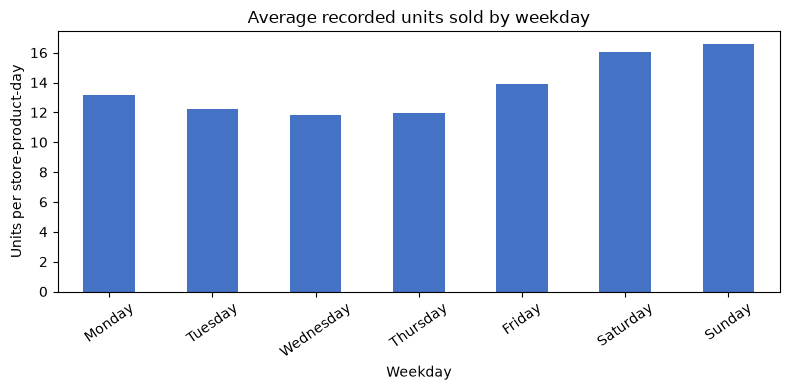

In [84]:
if __name__ == "__main__":
    weekday_means = analysis.groupby("weekday_name").units_sold.mean().reindex(WEEKDAY_ORDER)
    fig, ax = plt.subplots(figsize=(8, 4))
    weekday_means.plot(kind="bar", ax=ax, color="#4472c4")
    ax.set(title="Average recorded units sold by weekday", ylabel="Units per store-product-day", xlabel="Weekday")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    plt.show()



This is a descriptive comparison, not a causal estimate. Promotion dates are not randomly assigned, and the simulated demand process includes an assumed price and promotion response.



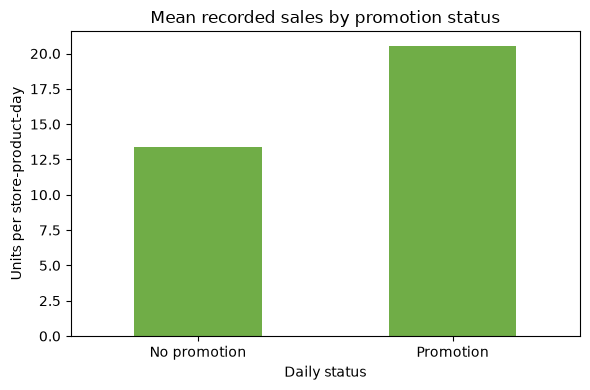

In [85]:
if __name__ == "__main__":
    promotion_means = analysis.groupby("is_promotion").units_sold.mean().reindex([False, True])
    fig, ax = plt.subplots(figsize=(6, 4))
    promotion_means.rename(index={False: "No promotion", True: "Promotion"}).plot(kind="bar", ax=ax, color="#70ad47")
    ax.set(title="Mean recorded sales by promotion status", ylabel="Units per store-product-day", xlabel="Daily status")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()
    plt.show()



## 5. Evaluate a simple weekday baseline
Use the final 21 dates as a chronological holdout. Estimate each store-product-weekday mean from earlier dates only.



In [86]:
def evaluate_baseline(analysis):
    cutoff = analysis.date.max() - pd.DateOffset(days=20)
    train = analysis[analysis.date < cutoff].copy()
    test = analysis[analysis.date >= cutoff].copy()
    train["weekday"] = train.date.dt.dayofweek
    test["weekday"] = test.date.dt.dayofweek
    baseline = train.groupby(["store_id", "product_id", "weekday"]).units_sold.mean().rename("forecast")
    test = test.join(baseline, on=["store_id", "product_id", "weekday"])
    assert test.forecast.notna().all()
    errors = test.units_sold - test.forecast
    metrics = pd.DataFrame([
        {"metric": "MAE", "value": errors.abs().mean()},
        {"metric": "WAPE", "value": errors.abs().sum() / test.units_sold.sum()},
        {"metric": "holdout_rows", "value": len(test)},
    ])
    return train, test, metrics


if __name__ == "__main__":
    train, test, metrics = evaluate_baseline(analysis)
    print(f"Training dates: {train.date.min().date()} to {train.date.max().date()}")
    print(f"Holdout dates: {test.date.min().date()} to {test.date.max().date()}")
    print(metrics.to_string(index=False))



Training dates: 2025-01-01 to 2025-04-09
Holdout dates: 2025-04-10 to 2025-04-30
      metric      value
         MAE   3.436154
        WAPE   0.241206
holdout_rows 525.000000


/tmp/ipykernel_1179084/1858696553.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  train["weekday"] = train.date.dt.dayofweek
/tmp/ipykernel_1179084/1858696553.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  test["weekday"] = test.date.dt.dayofweek


## 6. Findings and limitations
Use the calculated tables and charts to describe patterns. Keep conclusions specific to this synthetic dataset.



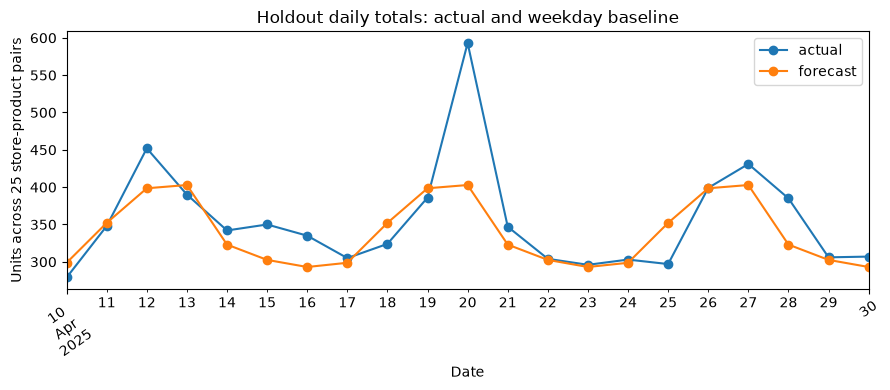

Saved six analysis tables to /home/ken/Documents/EIF/legacy/Sprint1/analysis_outputs


In [87]:
if __name__ == "__main__":
    daily_totals = test.groupby("date").agg(actual=("units_sold", "sum"), forecast=("forecast", "sum"))
    fig, ax = plt.subplots(figsize=(9, 4))
    daily_totals.plot(ax=ax, marker="o")
    ax.set(title="Holdout daily totals: actual and weekday baseline", ylabel="Units across 25 store-product pairs", xlabel="Date")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    plt.show()

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    calibration.to_csv(OUTPUT_DIR / "weekday_calibration.csv", index=False)
    store_product.to_csv(OUTPUT_DIR / "store_product_summary.csv", index=False)
    promotion_summary.to_csv(OUTPUT_DIR / "promotion_summary.csv", index=False)
    stockouts.to_csv(OUTPUT_DIR / "stockout_rows.csv", index=False)
    metrics.to_csv(OUTPUT_DIR / "forecast_metrics.csv", index=False)
    overall.to_csv(OUTPUT_DIR / "overall_metrics.csv", index=False)
    print(f"Saved six analysis tables to {OUTPUT_DIR}")


All records are synthetic. The M5 reference informs weekday shape but differs in retailer, geography, product mix, and period. Promotion, holiday, inventory, and demand-rate assumptions remain simplified. Forecast metrics measure this generated holdout only and do not establish real-world performance.
